## Exploratory Data Analysis

### Import Dependencies

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

NAMA_KELAS = {0: "NGR", 1: "Prediabetes", 2: "DM"}
WARNA = ["#2a78d6", "#eb6834", "#1baf7a"]

### Load Data

sel berisi spasi diubah dulu jadi nan, lalu diubah jadi angka, kecuali 3 kolom teks: data (tgl), EscDrinkD (penyakit yang bikin orang berhenti minum alkohol), dan EyeDia (ringkasan diagnosis mata).

In [2]:
KOLOM_TEKS = ["Data", "EscDrinkD", "EyeDia"]

df = pd.read_csv("data/Dataset for diabetes research.csv", encoding="gbk", dtype=str)
df = df.replace(r"^\s*$", np.nan, regex=True)

kolom_angka = df.columns.drop(KOLOM_TEKS)
df[kolom_angka] = df[kolom_angka].apply(pd.to_numeric, errors="coerce")

print("jumlah baris (orang):", df.shape[0])
print("jumlah kolom        :", df.shape[1])
df.head()

jumlah baris (orang): 5922
jumlah kolom        : 190


,Data,NO,VAR00001,Gender,Age,Age3Group,AgeGroup,Height,Weight,BMI,BMI4Class,overweight,obesity,WGOCobBMI,BMI25,waist1,WC9085,WC8580,WC9080,Waist2,hip,WHR,leg,HR,Bpsys,...,Compl,Check,GlucoseLev,DF,MADPN,TFDPN,DR,EyeDia,GAnum,filter,GAstudy,A1cover6575,DMhighrisk,FPGover7,P2PGover11,DRyd,cataract,GFR,GFR5lev,GFR6levG5,EUGFRabACR012,EUGFR90UACR01,EUGFR60abACR012,UACRGFR,DN
0,2/14/2012,733,1,1,31,1,2,168.0,65.5,23.207200,0.0,0.0,0.0,0.0,0.0,78.0,0.0,0.0,0.0,88.0,96.0,0.812500,NaN,78.0,110.0,...,9,9,9,1.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,1.0,1.0,0,0.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
1,2/11/2012,70,1,1,43,2,3,156.0,45.4,18.655490,0.0,0.0,0.0,0.0,0.0,74.0,0.0,0.0,0.0,84.0,88.0,0.840909,NaN,72.0,110.0,...,9,9,9,1.0,0.0,0.0,0.0,0,NaN,NaN,NaN,1.0,NaN,0,0.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
2,2/11/2012,98,1,1,57,2,4,163.0,69.1,26.007753,1.0,1.0,0.0,1.0,1.0,89.0,0.0,1.0,0.0,92.0,104.0,0.855769,NaN,72.0,110.0,...,1,2,2,1.0,0.0,0.0,0.0,0,NaN,NaN,NaN,1.0,1.0,0,0.0,0,0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN
3,2/11/2012,127,1,1,69,3,5,163.0,57.7,21.717039,0.0,0.0,0.0,0.0,0.0,86.0,0.0,1.0,0.0,86.0,93.0,0.924731,NaN,72.0,120.0,...,2,2,2,1.0,0.0,0.0,0.0,左眼人工晶体,1.0,NaN,1.0,1.0,1.0,0,0.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
4,2/11/2012,129,1,1,46,2,3,170.0,60.0,20.761246,0.0,0.0,0.0,0.0,0.0,76.0,0.0,0.0,0.0,86.0,96.0,0.791667,NaN,76.0,120.0,...,2,1,9,1.0,0.0,0.0,0.0,0,1.0,NaN,1.0,1.0,1.0,0,0.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN


In [3]:
tanggal = pd.to_datetime(df["Data"], format="%m/%d/%Y")
print("survei dilakukan:", tanggal.min().date(), "s/d", tanggal.max().date())
print("id duplikasi    :", df["NO"].duplicated().sum())
print("id terbesar     :", df["NO"].max())
print("jumlah data     :", len(df), "orang")

survei dilakukan: 2012-02-10 s/d 2012-04-07
id duplikasi    : 0
id terbesar     : 6571
jumlah data     : 5922 orang


di kamus data (docx), gender 0 = perempuan, 1 = laki-laki. tapi di data isinya 1 dan 2.

In [4]:
df.groupby("Gender")[["Height", "HGB", "Fat"]].median()

,Height,HGB,Fat
Gender,,,
1,161.0,155.0,18.6
2,152.0,135.0,28.7


kode 1 = laki-laki karena lebih tinggi, bb lebih tinggi, lemak tubuh lebih rendah, dan 2 = perempuan.

- id sampe 6.571 padahal datanya 5.922 orang. ada 649 orang yg tidak ada di data.

### Missing Value

kolom tanpa data kosong   : 23
kolom kosong lebih dari 50%: 21


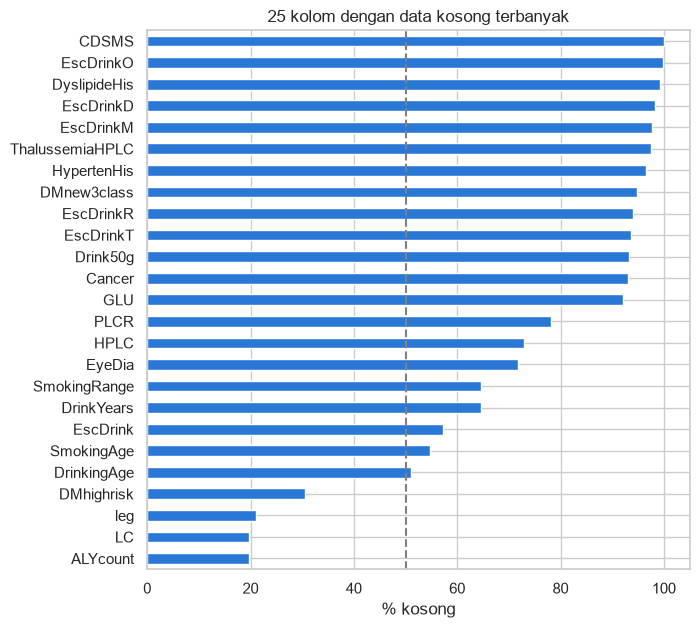

In [5]:
persen_kosong = df.isna().mean().mul(100).sort_values(ascending=False)

print("kolom tanpa data kosong   :", (persen_kosong == 0).sum())
print("kolom kosong lebih dari 50%:", (persen_kosong > 50).sum())

persen_kosong.head(25).plot.barh(figsize=(7, 7), color=WARNA[0])
plt.gca().invert_yaxis()
plt.axvline(50, color="gray", ls="--")
plt.title("25 kolom dengan data kosong terbanyak")
plt.xlabel("% kosong")
plt.show()

tidak semua kosong artinya data hilang:
1. kosong karena tidak ditanya, misal "umur mulai merokok" cuma ditanyakan ke perokok.
2. kosong artinya tidak. beberapa kolom cuma diisi angka 1 kalau jawabannya ya. contoh: hypertenhis (riwayat hipertensi),yang kosongnya diisi 0.

In [6]:
for kolom in ["HypertenHis", "DyslipideHis", "DMhighrisk"]:
    print(kolom, "sebelum:", df[kolom].value_counts(dropna=False).to_dict())

df[["HypertenHis", "DyslipideHis", "DMhighrisk"]] = df[["HypertenHis", "DyslipideHis", "DMhighrisk"]].fillna(0)

HypertenHis sebelum: {nan: 5722, 1.0: 200}
DyslipideHis sebelum: {nan: 5880, 1.0: 42}
DMhighrisk sebelum: {1.0: 4115, nan: 1807}


### Distribusi Target

label yg dipakai: PGclass3 (0 = NGR, 1 = Prediabetes, 2 = DM)
tujuan: mencari orang yg belum tahu dirinya diabetes/prediabetes. 

jadi orang yg sudah pernah didiagnosis DM (DMhis = 1) dikeluarkan.

data awal : 5922 orang
df_scr    : 5873 orang ( 49 orang yg sudah tahu DM dikeluarkan)


,jumlah,persen
PGclass3,,
NGR,4444,75.7
Prediabetes,1121,19.1
DM,308,5.2


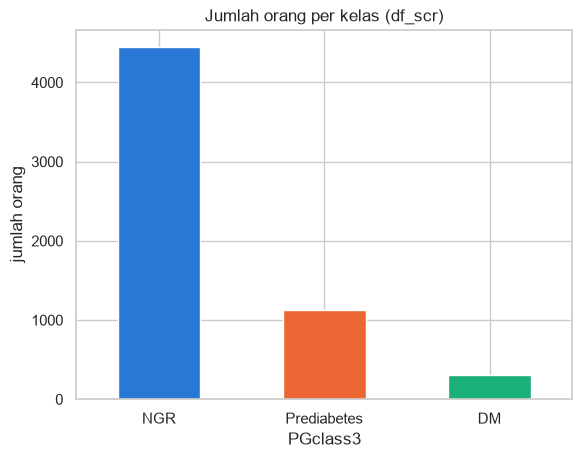

In [7]:
df_scr = df[df["DMhis"] == 0].copy()
print("data awal :", len(df), "orang")
print("df_scr    :", len(df_scr), "orang (", len(df) - len(df_scr), "orang yg sudah tahu DM dikeluarkan)")

jumlah = df_scr["PGclass3"].map(NAMA_KELAS).value_counts()
persen = (jumlah / jumlah.sum() * 100).round(1)
display(pd.DataFrame({"jumlah": jumlah, "persen": persen}))

jumlah.plot.bar(color=WARNA, rot=0)
plt.title("Jumlah orang per kelas (df_scr)")
plt.ylabel("jumlah orang")
plt.show()

orang sehat (NGR) jauh lebih banyak, 14 kali jumlah DM.

### Leak Feature

#### Gula Darah

label dibuat pakai aturan WHO 1999:
1. DM kalau FPG ≥ 7,0 atau PG2h ≥ 11,1 (atau sudah punya riwayat DM)
2. Prediabetes kalau FPG ≥ 6,1 atau PG2h ≥ 7,8
3. sisanya NGR

In [8]:
kondisi_dm = (df["FPG"] >= 7.0) | (df["PG2h"] >= 11.1) | (df["DMhis"] == 1)
kondisi_pre = (df["FPG"] >= 6.1) | (df["PG2h"] >= 7.8)
label_tebakan = np.select([kondisi_dm, kondisi_pre], [2, 1], default=0)

cocok = (label_tebakan == df["PGclass3"]).sum()
print(f"label hasil aturan WHO sama dengan label asli: {cocok} dari {len(df)} orang")

label hasil aturan WHO sama dengan label asli: 5922 dari 5922 orang


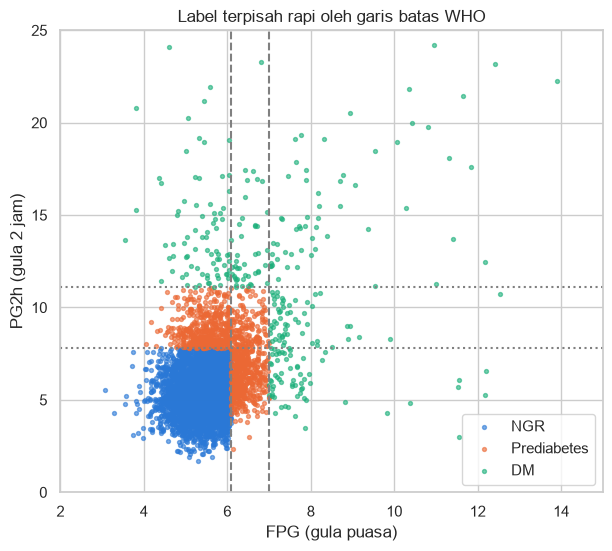

In [9]:
plt.figure(figsize=(7, 6))
for kelas, nama in NAMA_KELAS.items():
    d = df[df["PGclass3"] == kelas]
    plt.scatter(d["FPG"], d["PG2h"], s=8, alpha=0.6, color=WARNA[kelas], label=nama)
plt.axvline(6.1, color="gray", ls="--"); plt.axvline(7.0, color="gray", ls="--")
plt.axhline(7.8, color="gray", ls=":"); plt.axhline(11.1, color="gray", ls=":")
plt.xlim(2, 15); plt.ylim(0, 25)
plt.xlabel("FPG (gula puasa)"); plt.ylabel("PG2h (gula 2 jam)")
plt.title("Label terpisah rapi oleh garis batas WHO")
plt.legend()
plt.show()

leak feature karena label 100 bisa dihitung ulang dari FPG dan PG2h. 

#### VAR00001

isinya cuma 1 atau 9

In [10]:
pd.crosstab(df["VAR00001"], df["PGclass3"].map(NAMA_KELAS))[["NGR", "Prediabetes", "DM"]]

PGclass3,NGR,Prediabetes,DM
VAR00001,,,
1,4444,637,246
9,0,484,111


nilai 9 tidak pernah muncul di orang sehat (NGR), hanya di prediabetes dan DM. 

#### ThalussemiaAND

thalassemia: kelainan darah

In [11]:
pd.crosstab(df["ThalussemiaAND"], df["PGclass3"].map(NAMA_KELAS))[["NGR", "Prediabetes", "DM"]]

PGclass3,NGR,Prediabetes,DM
ThalussemiaAND,,,
0.0,4442,822,260
1.0,2,290,81


nilai 1 cuma ada 2 orang di NGR, tapi ratusan di prediabetes & DM. kolom ini cuma diisi untuk orang yg gula darahnya tidak normal.

#### Conclusion

In [12]:
BOCOR = [
    "FPG", "PG2h", "GLU", "DMhis",                       # gula darah & riwayat DM 
    "HomaIR", "Homaβ", "ISIGutt", "INS2h", "CP2h",      # dihitung dari gula darah / butuh tes OGTT
    "FPGover7", "P2PGover11",                            # penanda FPG / PG2h tinggi
    "DM", "DMnew3class", "PGclass6", "PGclass3",         # label itu sendiri
    "VAR00001", "ThalussemiaAND",                        
]
TIDAK_DIPAKAI = [
    "HbA1c", "HPLC", "GA", "A1cover6575",                # tes gula darah lain
    "filter", "GAstudy", "GAnum",                        # penanda subjek studi
    "Known", "OPD", "ToChilren", "DietExcise", "Compl", "Check", "GlucoseLev",  # kuesioner, mayoritas "tidak tahu"
    "DF", "MADPN", "TFDPN", "DR", "DRyd",                # komplikasi diabetes
    "CDSMS",                                             # 100% kosong
]
print("kolom bocor        :", len(BOCOR))
print("kolom tidak dipakai:", len(TIDAK_DIPAKAI))

kolom bocor        : 17
kolom tidak dipakai: 20


### Used Features

kolom yang dibuang:
- kolom teks dan id
- kolom yg kosong lebih dari 50%
- kolom yg isinya cuma 1 nilai atau tidak ada variasi
- ALT.1 (isinya cuma akar dari ALT, jadi double)

In [13]:
buang = set(BOCOR + TIDAK_DIPAKAI + KOLOM_TEKS + ["NO", "ALT.1"])
kosong_banyak = df.columns[df.isna().mean() > 0.5]
cuma_satu_nilai = df_scr.columns[df_scr.nunique() <= 1]

fitur = [c for c in df.columns if c not in buang and c not in kosong_banyak and c not in cuma_satu_nilai]
print("jumlah fitur yg tersisa:", len(fitur))

jumlah fitur yg tersisa: 135


### Feature Distribution

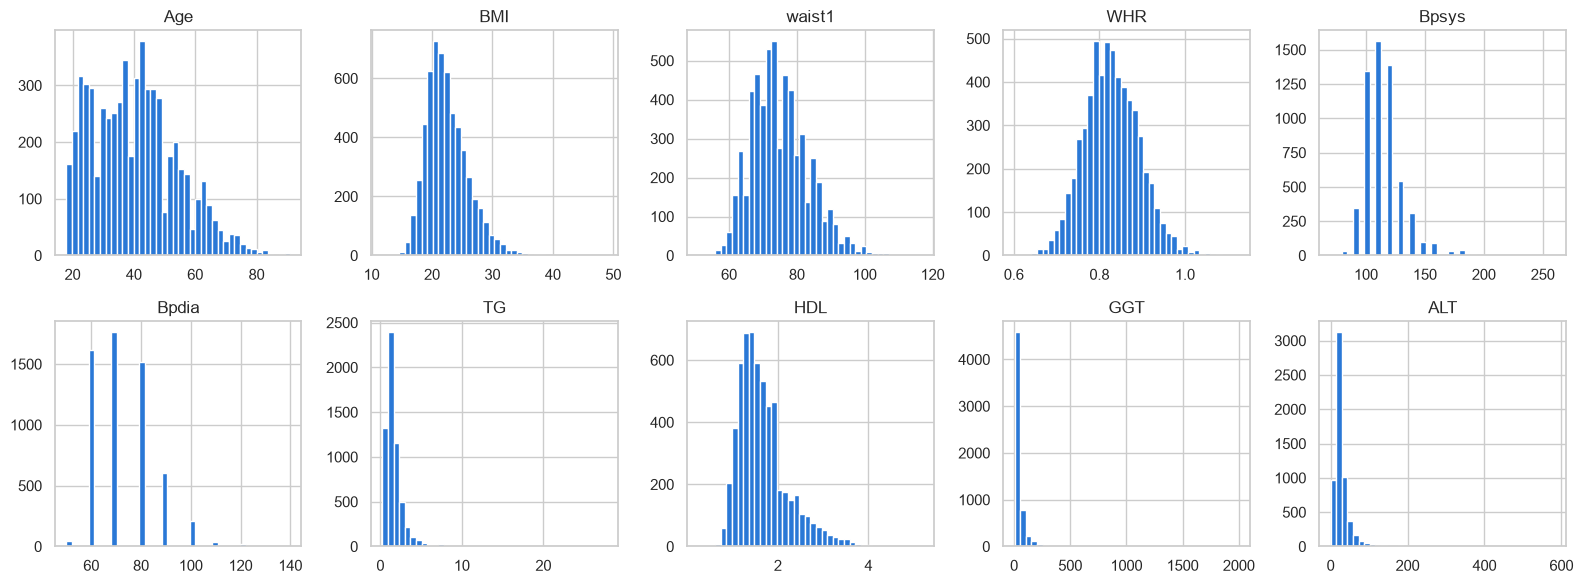

In [14]:
FITUR_UTAMA = ["Age", "BMI", "waist1", "WHR", "Bpsys", "Bpdia", "TG", "HDL", "GGT", "ALT"]

fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, kolom in zip(axes.flat, FITUR_UTAMA):
    ax.hist(df[kolom].dropna(), bins=40, color=WARNA[0])
    ax.set_title(kolom)
plt.tight_layout()
plt.show()

- Age = umur
- BMI = indeks massa tubuh
- waist1 = lingkar pinggang
- WHR = rasio pinggang-pinggul
- Bpsys/Bpdia = tensi atas/bawah
- TG = trigliserida
- HDL = kolesterol baik
- GGT dan ALT = enzim hati

 beberapa hasil lab (TG, GGT, ALT) miring ke kanan: kebanyakan orang nilainya kecil, sedikit orang nilainya sangat besar

### Feature Comparison

fitur apa yg beda antara orang sehat, prediabetes, dan DM, tanpa tes gula darah?

#### Fitur Angka

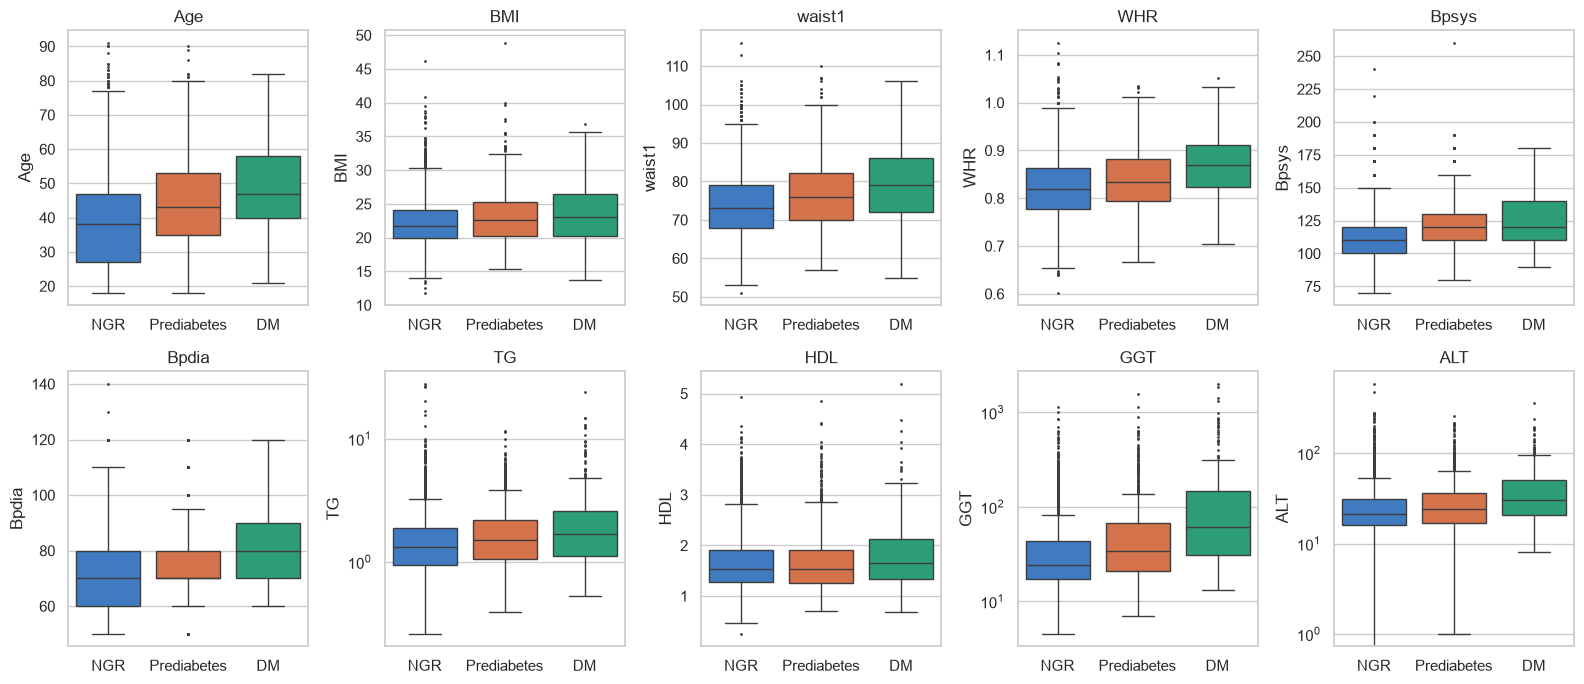

In [15]:
df_scr["kelas"] = df_scr["PGclass3"].map(NAMA_KELAS)
urutan = ["NGR", "Prediabetes", "DM"]

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, kolom in zip(axes.flat, FITUR_UTAMA):
    sns.boxplot(data=df_scr, x="kelas", y=kolom, order=urutan, hue="kelas", hue_order=urutan,
                palette=WARNA, ax=ax, fliersize=1, legend=False)
    ax.set_title(kolom); ax.set_xlabel("")
    if kolom in ["TG", "GGT", "ALT"]:
        ax.set_yscale("log")   
plt.tight_layout()
plt.show()

In [16]:
df_scr.groupby("kelas")[FITUR_UTAMA].median().loc[urutan].T.round(2)

kelas,NGR,Prediabetes,DM
Age,38.00,43.00,47.00
BMI,21.70,22.61,23.08
waist1,73.00,76.00,79.00
WHR,0.82,0.83,0.87
Bpsys,110.00,120.00,120.00
Bpdia,70.00,70.00,80.00
TG,1.32,1.50,1.69
HDL,1.54,1.54,1.65
GGT,24.00,34.00,61.00
ALT,21.00,24.00,30.00


#### Categorical

In [17]:
kategori = pd.DataFrame({
    "laki-laki (%)": df_scr["Gender"] == 1,
    "tensi tinggi, BP13085 (%)": df_scr["BP13085"] == 1,
    "obesitas perut, WC9085 (%)": df_scr["WC9085"] == 1,
    "kelompok risiko tinggi, DMhighrisk (%)": df_scr["DMhighrisk"] == 1,
    "riwayat DM keluarga (%)": df_scr["DMfamilyHistory"] == 1,
})
(kategori.groupby(df_scr["kelas"]).mean() * 100).loc[urutan].T.round(1)

kelas,NGR,Prediabetes,DM
laki-laki (%),43.6,52.5,69.5
"tensi tinggi, BP13085 (%)",18.8,30.2,51.9
"obesitas perut, WC9085 (%)",6.4,12.0,24.4
"kelompok risiko tinggi, DMhighrisk (%)",65.1,80.2,89.6
riwayat DM keluarga (%),1.6,1.9,2.3


- DM vs NGR bedanya cukup jelas: orang DM lebih tua, tensinya lebih tinggi, pinggangnya lebih besar, dan enzim hati GGT-nya jauh lebih tinggi. proporsi laki-laki juga lebih banyak di DM.
- Prediabetes vs NGR bedanya tipis: polanya sama tapi selisihnya kecil. jadi, prediabetes kemungkinan paling susah dideteksi tanpa tes gula darah.

### Outlier

cek nilai yg tidak masuk akal secara medis

In [18]:
print("tinggi < 120 cm                 :", (df["Height"] < 120).sum())
print("tensi atas <= tensi bawah       :", (df["Bpsys"] <= df["Bpdia"]).sum())
print("LDL > kolesterol total          :", (df["LDL"] > df["CHOL"]).sum())
print("kreatinin < 35 (terlalu rendah) :", (df["SCRE"] < 35).sum())
print("eGFR > 200 (terlalu tinggi)     :", (df["GFR"] > 200).sum())

tinggi < 120 cm                 : 2
tensi atas <= tensi bawah       : 2
LDL > kolesterol total          : 3
kreatinin < 35 (terlalu rendah) : 330
eGFR > 200 (terlalu tinggi)     : 376


kreatinin (SCRE): terlalu banyak yang nilainya terlalu rendah untuk orang dewasa. karena eGFR (GFR) dihitung dari kreatinin, eGFR mereka jadi terlalu tinggi. 

1. data: 5.922 orang × 190 kolom, survei Feb–Apr 2012. Gender: 1 = laki-laki, 2 = perempuan.
2. missing value: banyak kolom kosong, tapi sebagian kosongnya wajar atau artinya "tidak" (sudah diisi 0).
3. imbalanced class.
4. leakage: kolom FPG dan PG2h. semua kolom gula darah, turunannya, VAR00001, dan ThalussemiaAND.
5. DM bisa dibedakan lewat umur, tensi, lingkar pinggang, dan GGT. prediabetes jauh lebih sulit dibedakan dari orang sehat.
7. outlier: kreatinin dan eGFR banyak yg tidak masuk akal.

belum cek redundansi fitur, bmi punya 5 versi kategori

### Feature Redundancy

#### BMI

selain kolom BMI (angka), ada 5 kolom lain yg isinya cuma potongan dari BMI.

In [19]:
versi_bmi = ["BMI", "BMI4Class", "overweight", "obesity", "BMI25", "WGOCobBMI"]
print("yg masih ada di fitur:", [c for c in versi_bmi if c in fitur])

df_scr.groupby("BMI4Class")["BMI"].agg(["min", "max", "count"])

yg masih ada di fitur: ['BMI', 'BMI4Class', 'overweight', 'obesity', 'BMI25', 'WGOCobBMI']


,min,max,count
BMI4Class,,,
-1.0,11.800639,18.497159,544
0.0,18.501784,24.999036,4014
1.0,25.015609,29.982423,1018
2.0,30.000000,48.846881,186


tiap kelas BMI4Class cuma rentang angka BMI. kalau BMI (angka) sudah dipakai, BMI4Class tidak menambah info baru. hal yg sama berlaku untuk overweight, obesity, BMI25, WGOCobBMI.

#### Feature Correlation

korelasi spearman:
- mendekati 1: kalau satu naik, yg lain ikut naik
- mendekati -1: kalau satu naik, yg lain turun
- mendekati 0: tidak ada hubungan

pakai spearman karena banyak fitur miring ke kanan dan banyak fitur kategori.

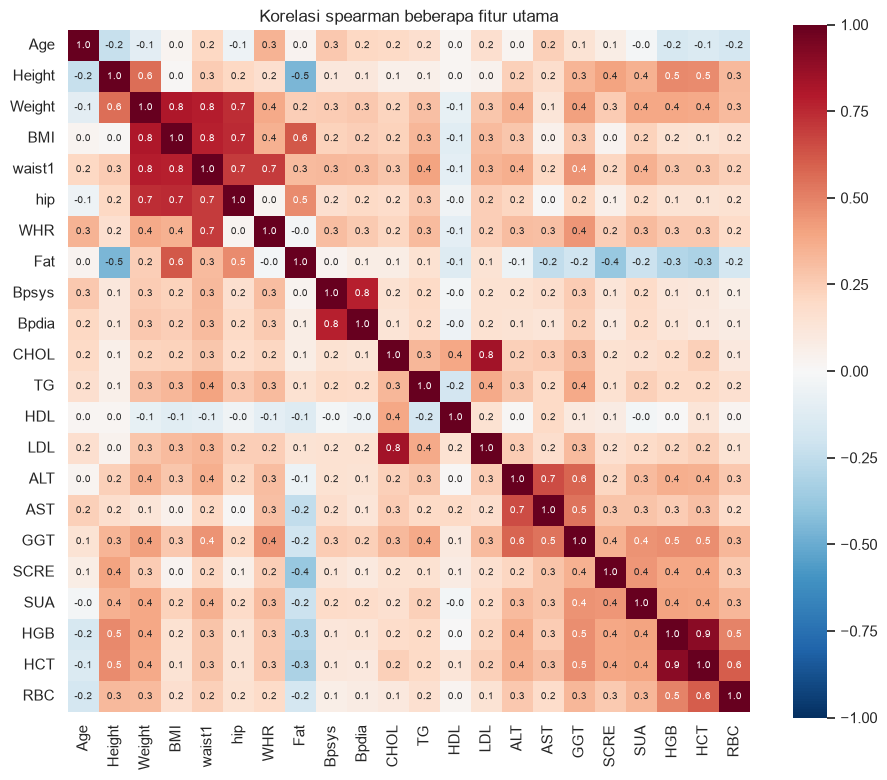

In [20]:
FITUR_KORELASI = ["Age", "Height", "Weight", "BMI", "waist1", "hip", "WHR", "Fat",
                  "Bpsys", "Bpdia", "CHOL", "TG", "HDL", "LDL", "ALT", "AST", "GGT",
                  "SCRE", "SUA", "HGB", "HCT", "RBC"]
korelasi = df_scr[FITUR_KORELASI].corr(method="spearman")

plt.figure(figsize=(11, 9))
sns.heatmap(korelasi, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".1f",
            annot_kws={"fontsize": 7}, square=True)
plt.title("Korelasi spearman beberapa fitur utama")
plt.show()

cek semua fitur, cari pasangan dengan korelasi |r| ≥ 0,9 (hampir sama isinya).

In [21]:
korelasi_semua = df_scr[fitur].corr(method="spearman")

pasangan = korelasi_semua.where(np.triu(np.ones(korelasi_semua.shape, dtype=bool), k=1)).stack().reset_index()
pasangan.columns = ["fitur_1", "fitur_2", "r"]
pasangan_tinggi = pasangan[pasangan["r"].abs() >= 0.9].sort_values("r", ascending=False).reset_index(drop=True)

print("jumlah pasangan |r| >= 0.9:", len(pasangan_tinggi))
pasangan_tinggi.round(3)

jumlah pasangan |r| >= 0.9: 56


,fitur_1,fitur_2,r
0,GFR5lev,GFR6levG5,1.000
1,ACR3degree,HighACR,1.000
2,EUGFR90UACR01,EUGFR60abACR012,0.999
3,HighUmALB,DN,0.997
4,CerebralHe,CerebralIn,0.986
5,CAP,Hypo14,0.983
6,LC,LCcount,0.981
7,PAD,Hyper16,0.978
8,CerebralHe,MI,0.978
9,MI,HF,0.978


banyak pasangan dari kolom riwayat penyakit (Angina, PAD, MI, HF, dll). kenapa?

In [22]:
RIWAYAT = ["Angina", "Arrhythmia", "PAD", "Hyper16", "Hyper13", "Blind", "CerebralHe", "CerebralIn",
           "TIA", "MI", "HF", "CAP", "Hypo14", "RF", "Amputation"]

semua_9 = (df_scr[RIWAYAT] == 9).all(axis=1).sum()
print(f"total pertanyaan riwayat penyakit: {len(RIWAYAT)}")
print(f"orang yg jawab \"9\" (tidak tahu): {semua_9}")

dua_duanya_riwayat = pasangan_tinggi["fitur_1"].isin(RIWAYAT) & pasangan_tinggi["fitur_2"].isin(RIWAYAT)
print("pasangan yg dua-duanya kolom riwayat penyakit:", dua_duanya_riwayat.sum())
print("pasangan sisanya:", (~dua_duanya_riwayat).sum())

total pertanyaan riwayat penyakit: 15
orang yg jawab "9" (tidak tahu): 689
pasangan yg dua-duanya kolom riwayat penyakit: 37
pasangan sisanya: 19


- 689 orang jawab "tidak tahu" (9) di semua pertanyaan riwayat penyakit. kolom-kolom tersebut berkorelasi bukan karena penyakitnya berhubungan, tapi karena kode 9.
- sisanya redundansi:
  - GFR5lev dan GFR6levG5: kategori GFR dengan pembagian beda
  - ACR3degree dan HighACR: kategori albumin urin
  - Age dan AgeGroup, Age3Group: umur dan kelompok umur
  - Smoking dan Smoking2: status merokok
  - LC dan LCcount, EO dan EOcount, ALY dan ALYcount: persen dan jumlah sel darah
  - TBIL dan IDBIL: bilirubin total dan bilirubin indirek
  - HGB dan HCT: hemoglobin dan hematokrit

## Preprocessing

tujuan: skrining dysglycemia (PGclass3: 0 = NGR, 1 = prediabetes, 2 = DM) tanpa tes gula darah.
kode preprocessing ada di notebook ini sendiri (sel bertanda `# [modul]` di bawah, tidak ada modul terpisah); sel-sel sesudahnya menjalankan dan memeriksanya.

dua tahap:
1. `prepare()`: aturan tetap, tidak memakai statistik data, aman dijalankan sebelum split.
2. `StatsCleaner`: langkah yang butuh statistik (kolom kosong, korelasi, skewness, imputasi). fit di data latih saja.

### Import

In [23]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 90)

#### from __future__ import annotations

kode di bagian ini adalah satu-satunya definisi fungsi preprocessing; sel-sel sesudahnya hanya memanggilnya. diberi tanda `# [modul]` supaya mudah dikenali.

In [24]:
# [modul]
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import GroupKFold, StratifiedKFold


#### Konstanta dan Konfigurasi

In [25]:
# [modul]
# ---------------------------------------------------------------- konstanta kolom
KOLOM_TEKS = ["Data", "EscDrinkD", "EyeDia"]
TARGET = "PGclass3"

# dipakai di notebook EDA: kolom gula darah, turunannya, dan label itu sendiri
BOCOR_GLUKOSA = [
    "FPG", "PG2h", "GLU", "HomaIR", "Homaβ", "ISIGutt", "INS2h", "CP2h", "FINS", "FCP",
    "FPGover7", "P2PGover11",
]
TES_GULA_LAIN = ["HbA1c", "HPLC", "GA", "A1cover6575"]
LABEL_DAN_TURUNAN = ["DM", "DMnew3class", "PGclass6", "PGclass3", "DMhis"]
PENANDA_SUBJEK = ["filter", "GAstudy", "GAnum"]
KOMPLIKASI_DM = ["DF", "MADPN", "TFDPN", "DR", "DRyd", "EyeDia"]
KUESIONER_TIDAK_TAHU = ["Known", "OPD", "ToChilren", "DietExcise", "Compl", "Check", "GlucoseLev"]

# kolom bocor yang sudah terbukti (bukan sifat pasien, melainkan turunan hasil tes / label)
FLAG_TURUNAN_TES = ["VAR00001", "ThalussemiaAND"]
ALASAN_BOCOR = {
    "VAR00001": "bocor: bernilai 9 hanya bila FPG >= 6,1 (69% dari FPG >= 6,1; tidak pernah pada FPG < 6,1)",
    "ThalussemiaAND": "bocor: bernilai 1 bila MCV < 80 DAN glukosa abnormal (kelas >= 1); 99,7% cocok",
}
# belum terbukti bocor: kebijakan bisa diganti (drop / keep) untuk ablasi
KOLOM_MENCURIGAKAN = ["ThalussemiaOR", "ThalussemiaHPLC", "DMhighrisk"]

# kolom bendera: hanya berisi 1 atau kosong. kosong diasumsikan "tidak" (seperti notebook EDA).
# asumsi ini belum bisa diverifikasi dari kamus data, jadi bisa dimatikan lewat Config.
BENDERA_ISI_NOL = ["HypertenHis", "DyslipideHis", "DMhighrisk", "ThalussemiaHPLC"]

ALASAN_MENCURIGAKAN = {
    "ThalussemiaOR": "ditahan: turunan hitung darah (MCV < 80), redundan dengan MCV/MCH",
    "ThalussemiaHPLC": "ditahan: bendera 1/kosong, hampir semua kosong; manfaat belum jelas",
    "DMhighrisk": "ditahan: komposit risiko, definisi tidak ada di kamus",
}

# satu konsep tampil dalam banyak versi kategori; versi numeriknya dipertahankan
TURUNAN_KATEGORI = {
    "BMI": ["BMI4Class", "overweight", "obesity", "BMI25", "WGOCobBMI"],
    "lingkar pinggang": ["WC9085", "WC8580", "WC9080"],
    "lemak tubuh": ["Fat2Class", "Fat3Class"],
    "umur": ["Age3Group", "AgeGroup"],
    "tekanan darah": ["BP13085", "WHO1999hbp"],
    "lipid": ["TGdis", "DysHDLIDFNCEP", "JCDHDLdis", "CDSdyelip"],
    "hati": ["ALTn", "TBILn", "FIB4n"],
    "ginjal": [
        "highCr", "HighUA", "HighUmALB", "ACR3degree", "HighACR", "GFR5lev", "GFR6levG5",
        "EUGFRabACR012", "EUGFR90UACR01", "EUGFR60abACR012", "UACRGFR", "DN",
    ],
    "darah": ["Hb4per", "Anemia"],
    "perilaku": ["Smoking2", "Drinking2"],
}

# bukan turunan kategori: duplikat transformasi dan ringkasan jawaban mentah
DUPLIKAT_TRANSFORMASI = {"ALT.1": "duplikat: akar kuadrat dari ALT"}
RIWAYAT_KELUARGA = ["FatherDM", "MotherDM", "BSDM", "ChildDM"]    # diringkas oleh DMfamilyHistory (OR keempatnya)

# kolom "kosong karena tidak ditanya": hanya ditanyakan ke perokok / peminum
# (kolom_nilai, kolom_penyaring, nilai_penyaring_yang_berarti_tidak)
KOSONG_STRUKTURAL = [
    ("SmokingRange", "Smoking", 1),
    ("DrinkYears", "Drinking", 1),
    ("Drink50g", "Drinking", 1),
]
KOSONG_STRUKTURAL_BUANG = [
    "SmokingAge", "DrinkingAge", "EscDrink", "EscDrinkM", "EscDrinkT", "EscDrinkR", "EscDrinkO",
]

# pertanyaan riwayat penyakit; kode 9 = "tidak tahu"
RIWAYAT = [
    "Angina", "Arrhythmia", "PAD", "Hyper16", "Hyper13", "Blind", "CerebralHe", "CerebralIn",
    "TIA", "MI", "HF", "CAP", "Hypo14", "RF", "Amputation",
]
KODE9_LAIN = ["WeightLoss", "Cancer"]


@dataclass
class Config:
    kebijakan_mencurigakan: str = "drop"   # "drop" | "keep" (ablasi thalassemia dan DMhighrisk)
    buang_flag_turunan_tes: bool = True    # False hanya untuk ablasi (VAR00001, ThalussemiaAND)
    buang_turunan_kategori: bool = True    # False = pertahankan semua versi kategori (ablasi)
    nol_kan_tidak_wajar: bool = True
    populasi_skrining: bool = True         # keluarkan yang sudah tahu DM (DMhis == 1)
    isi_nol_bendera: bool = True           # kosong pada kolom bendera (HypertenHis, dst.) = 0

    def __post_init__(self):
        if self.kebijakan_mencurigakan not in ("drop", "keep"):
            raise ValueError(f"kebijakan_mencurigakan harus 'drop' atau 'keep': {self.kebijakan_mencurigakan!r}")


#### Memuat Data

In [26]:
# [modul]
# ---------------------------------------------------------------- pemuatan data
def load_raw(path: str) -> pd.DataFrame:
    """Baca CSV (encoding GBK) seperti notebook EDA: spasi jadi NaN, kolom angka jadi numerik."""
    df = pd.read_csv(path, encoding="gbk", dtype=str)
    df = df.replace(r"^\s*$", np.nan, regex=True)
    kolom_angka = df.columns.drop(KOLOM_TEKS)
    df[kolom_angka] = df[kolom_angka].apply(pd.to_numeric, errors="coerce")
    df["Data"] = pd.to_datetime(df["Data"], format="%m/%d/%Y")
    return df


#### Tahap 1: aturan tetap (`prepare`)

In [27]:
# [modul]
# ---------------------------------------------------------------- tahap 1: aturan tetap
def prepare(df: pd.DataFrame, cfg: Config | None = None):
    """Aturan tetap. Mengembalikan (X, y, meta, laporan).

    X       : fitur (belum dibersihkan statistik)
    y       : PGclass3
    meta    : NO, Data (tanggal), glukosa referensi (FPG, PG2h) hanya untuk bukti kebocoran
    laporan : DataFrame kolom -> alasan dibuang, dan catatan perlakuan
    """
    cfg = cfg or Config()
    wajib = (["NO", "Data", TARGET, "DMhis", "FPG", "PG2h", "Gender", "SCRE", "GFR", "Height", "BMI",
              "Bpsys", "Bpdia", "LDL", "CHOL"] + RIWAYAT + KODE9_LAIN + BENDERA_ISI_NOL
             + [k for kolom, penyaring, _ in KOSONG_STRUKTURAL for k in (kolom, penyaring)])
    hilang = sorted(set(wajib) - set(df.columns))
    if hilang:
        raise ValueError(f"kolom wajib tidak ada di data (versi dataset berbeda?): {hilang}")
    df = df.copy()
    alasan: dict[str, str] = {}
    catatan: list[str] = []

    if cfg.populasi_skrining:
        n0 = len(df)
        df = df[df["DMhis"] == 0].copy()
        catatan.append(f"populasi skrining: {n0} -> {len(df)} orang (DMhis == 1 dikeluarkan)")
    df = df.reset_index(drop=True)

    y = df[TARGET].astype(int)
    meta = df[["NO", "Data", "FPG", "PG2h"]].copy()

    # jenis kelamin: kamus 0/1, data 1/2. di data 1 = laki-laki (tinggi, HGB lebih besar)
    kode_gender = set(df["Gender"].dropna().unique())
    if not kode_gender <= {1, 2}:
        raise ValueError(f"Gender harus berkode 1/2 (1 = laki-laki, seperti di data ini), ditemukan {sorted(kode_gender)}; kamus data menulis 0/1, periksa pengodean")
    df["male"] = (df["Gender"] == 1).astype(int)
    alasan["Gender"] = "diganti kolom male (1 = laki-laki)"

    # blok riwayat penyakit: jangan jadikan 15 kolom kosong, catat dalam satu penanda
    semua_9 = (df[RIWAYAT] == 9).all(axis=1)
    df["riwayat_tidak_diisi"] = semua_9.astype(int)
    catatan.append(f"riwayat_tidak_diisi: {int(semua_9.sum())} orang menjawab 9 di semua {len(RIWAYAT)} pertanyaan")
    semua_kosong = df[RIWAYAT].isna().all(axis=1)
    catatan.append(f"riwayat semua kosong (bukan 9): {int(semua_kosong.sum())} orang, tidak ditandai (lihat sel Verifikasi Asumsi)")
    for c in RIWAYAT + KODE9_LAIN:
        df.loc[df[c] == 9, c] = np.nan

    # kolom bendera: hanya 1 atau kosong, kosong diasumsikan "tidak"
    if cfg.isi_nol_bendera:
        for c in BENDERA_ISI_NOL:
            n_kosong = int(df[c].isna().sum())
            df[c] = df[c].fillna(0)
            catatan.append(f"{c}: {n_kosong} kosong diisi 0 (asumsi: kosong = tidak)")

    # kosong struktural: tidak ditanya karena memang tidak merokok / minum -> 0
    for kolom, penyaring, nilai in KOSONG_STRUKTURAL:
        m = df[kolom].isna() & (df[penyaring] == nilai)
        df.loc[m, kolom] = 0
        catatan.append(f"{kolom}: {int(m.sum())} kosong struktural ({penyaring} == {nilai}) diisi 0")

    # nilai tidak wajar -> NaN (dan kolom turunannya)
    if cfg.nol_kan_tidak_wajar:
        aturan = {
            "kreatinin < 35 (SCRE, GFR ikut)": (df["SCRE"] < 35, ["SCRE", "GFR"]),
            "eGFR > 200 (GFR)": (df["GFR"] > 200, ["GFR"]),
            "tinggi < 120 (Height, BMI)": (df["Height"] < 120, ["Height", "BMI"]),
            "tensi atas <= bawah": (df["Bpsys"] <= df["Bpdia"], ["Bpsys", "Bpdia"]),
            "LDL > kolesterol total (LDL dan CHOL)": (df["LDL"] > df["CHOL"], ["LDL", "CHOL"]),
        }
        for nama, (mask, kolom) in aturan.items():
            n = int(mask.sum())
            df.loc[mask, kolom] = np.nan
            catatan.append(f"tidak wajar: {nama}: {n} baris jadi NaN")

    # buang kolom berdasarkan alasan
    def buang(kolom, kenapa):
        for c in kolom:
            if c in df.columns and c not in alasan:
                alasan[c] = kenapa

    buang(["NO", "Data", TARGET], "id / tanggal / target (disimpan terpisah)")
    buang(["EscDrinkD", "EyeDia"], "kolom teks")
    buang(BOCOR_GLUKOSA, "bocor: gula darah atau dihitung dari gula darah")
    buang(TES_GULA_LAIN, "tes gula darah lain")
    buang(LABEL_DAN_TURUNAN, "label atau turunan label")
    buang(PENANDA_SUBJEK, "penanda subjek studi")
    buang(KOMPLIKASI_DM, "komplikasi diabetes (setelah diagnosis)")
    buang(KUESIONER_TIDAK_TAHU, "kuesioner kesadaran diabetes, mayoritas tidak tahu")
    if cfg.buang_flag_turunan_tes:
        for c in FLAG_TURUNAN_TES:
            buang([c], ALASAN_BOCOR[c])
    buang(KOSONG_STRUKTURAL_BUANG, "kosong struktural, informasi ada di kolom penyaring")
    if cfg.kebijakan_mencurigakan == "drop":
        for c in KOLOM_MENCURIGAKAN:
            buang([c], ALASAN_MENCURIGAKAN[c])
    if cfg.buang_turunan_kategori:
        for konsep, kolom in TURUNAN_KATEGORI.items():
            buang(kolom, f"turunan kategori dari versi numerik ({konsep})")
        for c, kenapa in DUPLIKAT_TRANSFORMASI.items():
            buang([c], kenapa)
        buang(RIWAYAT_KELUARGA, "jawaban mentah per kerabat, diringkas oleh DMfamilyHistory")
    df = df.drop(columns=[c for c in alasan if c in df.columns])
    # kolom konstan sebelum statistik apa pun
    konstan = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]
    for c in konstan:
        if df[c].notna().any() and df[c].isna().any():
            alasan[c] = "hanya bernilai satu nilai atau kosong (bendera); terbuang karena kosong tidak diisi 0"
        else:
            alasan[c] = "kosong semua" if df[c].notna().sum() == 0 else "konstan"
    df = df.drop(columns=konstan)

    laporan = pd.DataFrame({"kolom": list(alasan), "alasan": list(alasan.values())})
    laporan.attrs["catatan"] = catatan
    return df, y, meta, laporan


#### Tahap 2: dengan statistik (`StatsCleaner`)

In [28]:
# [modul]
# ---------------------------------------------------------------- tahap 2: dengan statistik
class StatsCleaner(TransformerMixin, BaseEstimator):
    """Langkah yang butuh statistik data. Fit pada data latih saja.

    urutan : buang kolom terlalu kosong -> buang kolom biner sangat jarang -> buang pasangan
             berkorelasi tinggi -> log1p untuk kolom miring -> imputasi
    imputasi: "none" (NaN dibiarkan, mis. untuk TabPFN), "median", atau "iterative".
              kolom biner selalu diisi modus data latih (tetap pada nilai aslinya); kolom lain median atau iteratif.
    """

    def __init__(self, maks_kosong=0.5, min_minoritas=10, korelasi=0.95, skew=2.0, imputasi="none", min_periods_korelasi=100):
        self.maks_kosong = maks_kosong
        self.min_minoritas = min_minoritas
        self.korelasi = korelasi
        self.skew = skew
        self.imputasi = imputasi
        self.min_periods_korelasi = min_periods_korelasi      # pasangan yang tumpang tindih kurang dari ini tidak dinilai (rho dari 3 baris tak berarti)

    def fit(self, X: pd.DataFrame, y=None):
        if self.imputasi not in ("none", "median", "iterative"):
            raise ValueError(f"imputasi tidak dikenal: {self.imputasi!r}")
        X = X.copy()
        self.dibuang_: dict[str, str] = {}

        kosong = X.isna().mean()
        for c in kosong[(kosong > self.maks_kosong) | (kosong >= 1.0)].index:      # kolom kosong semua selalu dibuang
            self.dibuang_[c] = f"kosong {kosong[c]:.0%} (> {self.maks_kosong:.0%})" if kosong[c] < 1.0 else "kosong semua di data latih"
        X = X.drop(columns=list(self.dibuang_))

        for c in X.columns:
            nilai = X[c].dropna()
            if 0 < nilai.nunique() <= 2:
                minoritas = int(nilai.value_counts().min()) if nilai.nunique() == 2 else 0   # konstan = minoritas 0
                if minoritas < self.min_minoritas:
                    self.dibuang_[c] = f"biner terlalu jarang (minoritas = {minoritas})"
        X = X.drop(columns=[c for c in self.dibuang_ if c in X.columns])

        # pasangan sangat berkorelasi (spearman): buang yang lebih banyak kosong
        rho = X.corr(method="spearman", min_periods=self.min_periods_korelasi).abs()
        atas = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1))
        for c in atas.columns:
            for lain in atas.index[atas[c] >= self.korelasi]:
                if lain in self.dibuang_:
                    continue
                korban = c if X[c].isna().mean() > X[lain].isna().mean() else lain
                keep = lain if korban == c else c
                self.dibuang_[korban] = f"|rho| = {atas.loc[lain, c]:.3f} dengan {keep}"
                if korban == c:
                    break          # c sudah dibuang: jangan buang kolom lain karena c
        X = X.drop(columns=[c for c in self.dibuang_ if c in X.columns])

        self.kolom_ = list(X.columns)
        self.kolom_log_ = [
            c for c in X.columns
            if X[c].nunique() > 10 and X[c].min() >= 0 and X[c].skew() > self.skew
        ]
        if self.kolom_log_:
            X[self.kolom_log_] = np.log1p(X[self.kolom_log_])

        self.kolom_biner_ = [c for c in X.columns if 0 < X[c].dropna().nunique() <= 2]
        self.modus_ = {c: X[c].mode(dropna=True).iloc[0] for c in self.kolom_biner_}

        self.imputer_ = None
        if self.imputasi == "median":
            from sklearn.impute import SimpleImputer
            self.imputer_ = SimpleImputer(strategy="median").fit(X)
        elif self.imputasi == "iterative":
            import importlib
            importlib.import_module("sklearn.experimental.enable_iterative_imputer")   # mengaktifkan IterativeImputer
            from sklearn.impute import IterativeImputer
            self.imputer_ = IterativeImputer(max_iter=10, random_state=0).fit(X)
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        X = X[self.kolom_].copy()
        if self.kolom_log_:
            X[self.kolom_log_] = np.log1p(X[self.kolom_log_].clip(lower=0))
        if self.imputer_ is not None:
            kosong_biner = X[self.kolom_biner_].isna()
            X = pd.DataFrame(self.imputer_.transform(X), columns=self.kolom_, index=X.index)
            # kolom biner tetap pada nilai aslinya: sel yang tadinya kosong diisi modus data latih
            # (median dari 0/1 bisa 0,5; iterative memberi nilai kontinu)
            for c in self.kolom_biner_:
                X.loc[kosong_biner[c], c] = self.modus_[c]
        return X


#### Skema Pembagian Data

In [29]:
# [modul]
# ---------------------------------------------------------------- skema pembagian data
def buat_split(y: pd.Series, meta: pd.DataFrame, skema: str, n_lipatan: int = 5, seed: int = 0):
    """Kembalikan list (idx_latih, idx_uji).

    acak     : stratified k-fold
    tanggal  : GroupKFold per tanggal survei (hari yang sama tidak terbagi)
    temporal : 70% awal berdasar urutan ID untuk latih, 30% akhir untuk uji (n_lipatan dan seed tidak berlaku;
               skema tanggal juga tidak memakai seed).
               NB: skema tanggal hanya mencegah satu hari terbagi antara latih dan uji; ia mengacak urutan hari,
               jadi bukan uji pergeseran waktu. holdout temporal satu-satunya yang menguji pergeseran waktu. urutan ID hampir identik dengan
               urutan tanggal (spearman 0,9995; 2 pasangan mundur sampai 2 hari)
    """
    n = len(y)
    if skema == "acak":
        return list(StratifiedKFold(n_lipatan, shuffle=True, random_state=seed).split(np.zeros(n), y))
    if skema == "tanggal":
        return list(GroupKFold(n_lipatan).split(np.zeros(n), y, groups=meta["Data"].dt.strftime("%Y-%m-%d")))
    if skema == "temporal":
        if "Data" in meta and meta["Data"].notna().all():
            arah = meta["NO"].rank().corr(meta["Data"].rank())
            if not arah >= 0.9:      # NO dipakai sebagai urutan waktu: harus sejalan dengan tanggal
                raise ValueError(f"urutan NO tidak sejalan dengan tanggal (spearman {arah:.2f}); split temporal tidak bermakna")
        urut = np.argsort(meta["NO"].to_numpy())
        potong = int(n * 0.7)
        return [(urut[:potong], urut[potong:])]
    raise ValueError(f"skema tidak dikenal: {skema}")


#### Penerapan per Lipatan

In [30]:
# [modul]
# ---------------------------------------------------------------- pintu masuk untuk tahap modeling
def terapkan_lipatan(X: pd.DataFrame, idx_latih, idx_uji, imputasi: str = "none", **kwargs):
    """Fit StatsCleaner pada data latih, lalu transform data latih dan uji.

    imputasi: "none" (CatBoost, TabPFN), "median" atau "iterative" (Logistic Regression, MLP, FT-Transformer).
    kembalian: (X_latih, X_uji, cleaner)
    """
    cleaner = StatsCleaner(imputasi=imputasi, **kwargs).fit(X.iloc[idx_latih])
    return cleaner.transform(X.iloc[idx_latih]), cleaner.transform(X.iloc[idx_uji]), cleaner


#### Metrik Evaluasi

In [31]:
# [modul]
# ---------------------------------------------------------------- metrik evaluasi
def metrik_tiga_kelas(yt, p):
    """Metrik untuk tiga kelas (0 = NGR, 1 = prediabetes, 2 = DM) dari probabilitas p (n x 3).

    macro_auc : AUC one-vs-rest, rata-rata tiga kelas
    auc_dm    : AUC DM vs sisanya
    ap_dm     : PR-AUC (average precision) DM
    auc_pre_vs_normal : AUC prediabetes vs normal (DM dikeluarkan)
    """
    from sklearn.metrics import average_precision_score, roc_auc_score
    yt = np.asarray(yt)
    p = np.asarray(p)
    out = {
        "macro_auc": roc_auc_score(yt, p, multi_class="ovr", average="macro"),
        "auc_dm": roc_auc_score(yt == 2, p[:, 2]),
        "ap_dm": average_precision_score(yt == 2, p[:, 2]),
    }
    m = yt <= 1
    pembagi = p[m, 0] + p[m, 1]
    out["auc_pre_vs_normal"] = roc_auc_score(yt[m] == 1, np.divide(p[m, 1], pembagi, out=np.full(int(m.sum()), 0.5), where=pembagi > 0))
    return out


### Load Data

In [32]:
raw = load_raw("data/Dataset for diabetes research.csv")
print("data mentah:", raw.shape)

data mentah: (5922, 190)


### Aturan Tetap: prepare()

populasi: yang sudah tahu DM (DMhis = 1) dikeluarkan, karena tujuannya mencari yang belum tahu.

In [33]:
X, y, meta, laporan = prepare(raw)
print("fitur setelah prepare():", X.shape)
print("target:", y.map({0: "NGR", 1: "Prediabetes", 2: "DM"}).value_counts().to_dict())
print()
for baris in laporan.attrs["catatan"]:
    print("-", baris)

fitur setelah prepare(): (5873, 96)
target: {'NGR': 4444, 'Prediabetes': 1121, 'DM': 308}

- populasi skrining: 5922 -> 5873 orang (DMhis == 1 dikeluarkan)
- riwayat_tidak_diisi: 689 orang menjawab 9 di semua 15 pertanyaan
- riwayat semua kosong (bukan 9): 242 orang, tidak ditandai (lihat sel Verifikasi Asumsi)
- HypertenHis: 5681 kosong diisi 0 (asumsi: kosong = tidak)
- DyslipideHis: 5833 kosong diisi 0 (asumsi: kosong = tidak)
- DMhighrisk: 1805 kosong diisi 0 (asumsi: kosong = tidak)
- ThalussemiaHPLC: 5728 kosong diisi 0 (asumsi: kosong = tidak)
- SmokingRange: 2856 kosong struktural (Smoking == 1) diisi 0
- DrinkYears: 2494 kosong struktural (Drinking == 1) diisi 0
- Drink50g: 2530 kosong struktural (Drinking == 1) diisi 0
- tidak wajar: kreatinin < 35 (SCRE, GFR ikut): 327 baris jadi NaN
- tidak wajar: eGFR > 200 (GFR): 374 baris jadi NaN
- tidak wajar: tinggi < 120 (Height, BMI): 2 baris jadi NaN
- tidak wajar: tensi atas <= bawah: 2 baris jadi NaN
- tidak wajar: LDL > kolester

yang dikerjakan `prepare()`:
- `Gender` (kamus 0/1, data 1/2) diganti `male` (1 = laki-laki).
- 689 orang menjawab 9 di semua 15 pertanyaan riwayat penyakit. dibuat satu penanda `riwayat_tidak_diisi`, lalu kode 9 jadi NaN.
- `SmokingRange`, `DrinkYears`, `Drink50g` kosong karena tidak ditanya ke yang tidak merokok / minum, diisi 0.
- nilai tidak wajar jadi NaN: kreatinin < 35 (eGFR ikut, karena dihitung dari kreatinin), eGFR > 200, tinggi < 120, tensi atas <= bawah, LDL > kolesterol total.
- kode 9 pada `Cancer` juga jadi NaN (63 dari 409 jawaban).
- 242 orang lain mengosongkan seluruh 15 pertanyaan riwayat (bukan menjawab 9). mereka **tidak** ditandai `riwayat_tidak_diisi`, hanya tampak sebagai NaN.


#### Kolom yang dibuang dan alasannya

In [34]:
ringkas = laporan["alasan"].str.replace(r"\(.*\)", "", regex=True).str.strip().value_counts()
ringkas.to_frame("jumlah kolom")

,jumlah kolom
alasan,
turunan kategori dari versi numerik,37
bocor: gula darah atau dihitung dari gula darah,12
"kuesioner kesadaran diabetes, mayoritas tidak tahu",7
"kosong struktural, informasi ada di kolom penyaring",7
komplikasi diabetes,5
tes gula darah lain,4
label atau turunan label,4
"jawaban mentah per kerabat, diringkas oleh DMfamilyHistory",4
id / tanggal / target,3


In [35]:
for alasan, grup in laporan.groupby("alasan"):
    print(f"[{len(grup)}] {alasan}")
    print("    ", ", ".join(grup["kolom"]))

[1] bocor: bernilai 1 bila MCV < 80 DAN glukosa abnormal (kelas >= 1); 99,7% cocok
     ThalussemiaAND
[1] bocor: bernilai 9 hanya bila FPG >= 6,1 (69% dari FPG >= 6,1; tidak pernah pada FPG < 6,1)
     VAR00001
[12] bocor: gula darah atau dihitung dari gula darah
     FPG, PG2h, GLU, HomaIR, Homaβ, ISIGutt, INS2h, CP2h, FINS, FCP, FPGover7, P2PGover11
[1] diganti kolom male (1 = laki-laki)
     Gender
[1] ditahan: bendera 1/kosong, hampir semua kosong; manfaat belum jelas
     ThalussemiaHPLC
[1] ditahan: komposit risiko, definisi tidak ada di kamus
     DMhighrisk
[1] ditahan: turunan hitung darah (MCV < 80), redundan dengan MCV/MCH
     ThalussemiaOR
[1] duplikat: akar kuadrat dari ALT
     ALT.1
[3] id / tanggal / target (disimpan terpisah)
     NO, Data, PGclass3
[4] jawaban mentah per kerabat, diringkas oleh DMfamilyHistory
     FatherDM, MotherDM, BSDM, ChildDM
[2] kolom teks
     EscDrinkD, EyeDia
[5] komplikasi diabetes (setelah diagnosis)
     DF, MADPN, TFDPN, DR, DRyd
[1] k

### Verifikasi Asumsi

asumsi "kosong karena tidak ditanya" perlu dicek: apakah kosongnya benar hanya pada yang tidak merokok / minum?

In [36]:
df = raw[raw["DMhis"] == 0]
for kolom, penyaring in [("SmokingRange", "Smoking"), ("DrinkYears", "Drinking"), ("Drink50g", "Drinking")]:
    print(kolom, "kosong menurut", penyaring, "(1 = tidak, 2 = kadang, 3 = rutin):")
    print(pd.crosstab(df[penyaring], df[kolom].isna().rename("kosong")).to_string())
    print()

SmokingRange kosong menurut Smoking (1 = tidak, 2 = kadang, 3 = rutin):
kosong   False  True 
Smoking              
1.0          6   2856
2.0        276     68
3.0       1701    569

DrinkYears kosong menurut Drinking (1 = tidak, 2 = kadang, 3 = rutin):
kosong    False  True 
Drinking              
1.0          44   2494
2.0        1079    603
3.0         847    329

Drink50g kosong menurut Drinking (1 = tidak, 2 = kadang, 3 = rutin):
kosong    False  True 
Drinking              
1.0           8   2530
2.0          95   1587
3.0         288    888



- `SmokingRange` dan `DrinkYears`: hampir semua yang menjawab "tidak" kosong (2.856 dari 2.862 bukan perokok; 2.494 dari 2.538 bukan peminum), jadi diisi 0. kosong pada perokok dan peminum (24% dan 32%) dibiarkan NaN karena itu memang tidak diketahui.
- `Drink50g` (jumlah minum per kali): tetap kosong pada sebagian yang minum, jadi isinya tidak lengkap. kolom ini dibuang karena kosong > 50% (split temporal) atau berkorelasi tinggi dengan `Drinking` (di beberapa lipatan acak); tidak pernah dipakai.

### Skema Pembagian Data

tiga skema. urutan ID hampir sama dengan urutan tanggal survei (korelasi spearman 0,9995; hanya 2 pasangan berurutan yang mundur, paling jauh 2 hari), jadi `temporal` bisa dibuat dari ID.

In [37]:
for skema in ["acak", "tanggal", "temporal"]:
    lipatan = buat_split(y, meta, skema)
    info = [(len(tr), len(te), int((y.iloc[te] == 2).sum())) for tr, te in lipatan]
    print(f"{skema:9s} {len(lipatan)} lipatan | (latih, uji, DM di uji): {info}")
urut = meta.sort_values("NO")
selisih_hari = urut["Data"].diff().dt.days
print()
print("spearman urutan ID vs tanggal:", round(meta["NO"].rank().corr(meta["Data"].rank()), 4))
print("pasangan ID berurutan yang tanggalnya mundur:", int((selisih_hari < 0).sum()), "| paling jauh", int(-selisih_hari.min()), "hari")


acak      5 lipatan | (latih, uji, DM di uji): [(4698, 1175, 62), (4698, 1175, 62), (4698, 1175, 62), (4699, 1174, 61), (4699, 1174, 61)]
tanggal   5 lipatan | (latih, uji, DM di uji): [(4711, 1162, 54), (4692, 1181, 49), (4687, 1186, 61), (4693, 1180, 56), (4709, 1164, 88)]
temporal  1 lipatan | (latih, uji, DM di uji): [(4111, 1762, 69)]

spearman urutan ID vs tanggal: 0.9995
pasangan ID berurutan yang tanggalnya mundur: 2 | paling jauh 2 hari


### Tahap Statistik: StatsCleaner

dicoba pada skema `temporal` (70% awal untuk latih, 30% akhir untuk uji). semua statistik dihitung dari data latih saja.

In [38]:
tr, te = buat_split(y, meta, "temporal")[0]

hasil = {}
for imputasi in ["none", "median", "iterative"]:
    c = StatsCleaner(imputasi=imputasi).fit(X.iloc[tr])
    Xtr, Xte = c.transform(X.iloc[tr]), c.transform(X.iloc[te])
    hasil[imputasi] = (c, Xtr, Xte)
    print(f"imputasi = {imputasi:9s} latih {Xtr.shape}, uji {Xte.shape} | NaN latih {int(Xtr.isna().sum().sum()):6d}, uji {int(Xte.isna().sum().sum()):6d}")

c = hasil["none"][0]
print()
print("kolom dibuang di tahap statistik:", len(c.dibuang_))
pd.Series(c.dibuang_, name="alasan").to_frame()

imputasi = none      latih (4111, 82), uji (1762, 82) | NaN latih  19900, uji   7066


imputasi = median    latih (4111, 82), uji (1762, 82) | NaN latih      0, uji      0


imputasi = iterative latih (4111, 82), uji (1762, 82) | NaN latih      0, uji      0

kolom dibuang di tahap statistik: 14


,alasan
PLCR,kosong 78% (> 50%)
Drink50g,kosong 52% (> 50%)
Cancer,kosong 100% (> 50%)
HCVAb,biner terlalu jarang (minoritas = 6)
PAD,biner terlalu jarang (minoritas = 7)
CerebralHe,biner terlalu jarang (minoritas = 4)
TIA,biner terlalu jarang (minoritas = 6)
MI,biner terlalu jarang (minoritas = 2)
HF,biner terlalu jarang (minoritas = 5)
CAP,biner terlalu jarang (minoritas = 3)


In [39]:
c, Xtr, Xte = hasil["none"]
print("fitur akhir:", len(c.kolom_))
print("kolom di-log1p (skewness > 2):", c.kolom_log_)

fitur akhir: 82
kolom di-log1p (skewness > 2): ['ALT', 'AST', 'ASTALT', 'GGT', 'ALP', 'TBIL', 'DBIL', 'TG', 'BUN', 'SCRE', 'UmALB', 'UMAUCR', 'LCcount', 'ALY', 'ALYcount', 'RDWCV', 'BASO', 'BASOcount', 'EOcount', 'PLT', 'FIB4']


#### Kolom kosong setelah tahap statistik

In [40]:
sisa = Xtr.isna().mean().mul(100)
print(f"kolom: {X.shape[1]} (setelah prepare) -> {Xtr.shape[1]} (setelah tahap statistik)")
print(f"kolom yang masih punya NaN: {int((sisa > 0).sum())} dari {len(sisa)}; kosong maksimum {sisa.max():.1f}%")
sisa.sort_values(ascending=False).head(8).round(1).to_frame("kosong (%)")

kolom: 96 (setelah prepare) -> 82 (setelah tahap statistik)
kolom yang masih punya NaN: 76 dari 82; kosong maksimum 27.5%


,kosong (%)
WeightLoss,27.5
leg,27.2
Arrhythmia,25.4
Hyper16,25.3
Hyper13,25.1
RF,24.7
Angina,23.6
Blind,23.4


#### Sebelum dan sesudah: skewness

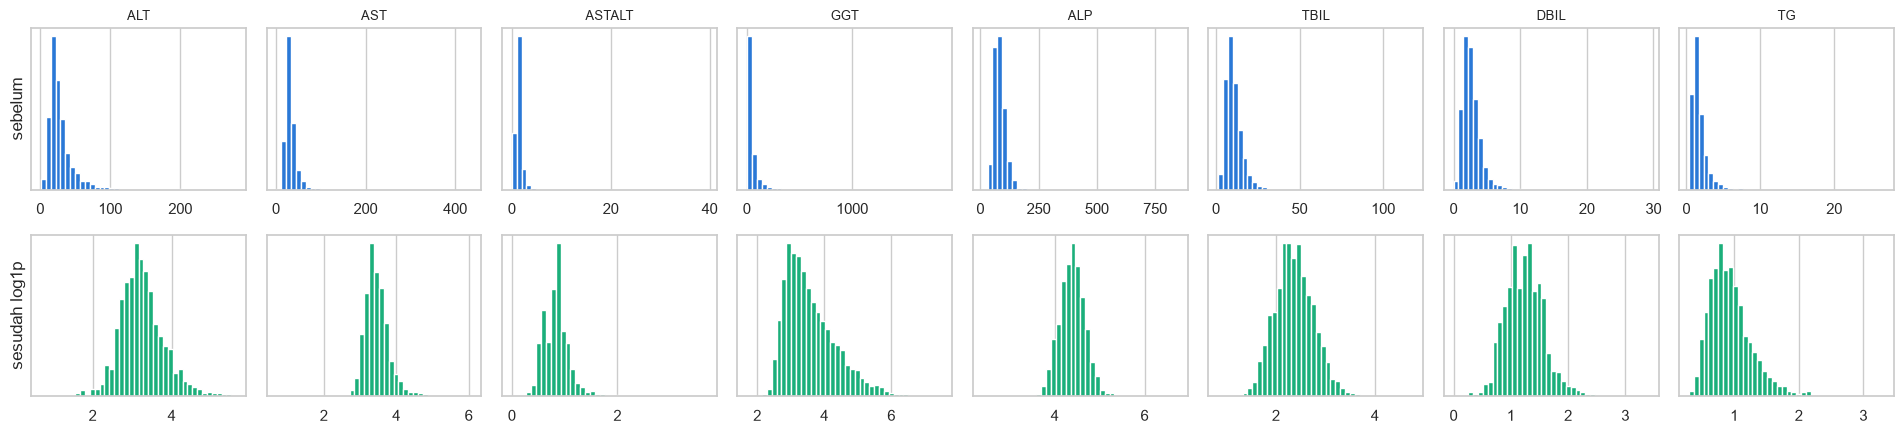

In [41]:
kolom = c.kolom_log_[:8]
fig, axes = plt.subplots(2, len(kolom), figsize=(2.4 * len(kolom), 4.5))
for j, k in enumerate(kolom):
    axes[0, j].hist(X.iloc[tr][k].dropna(), bins=40, color="#2a78d6")
    axes[0, j].set_title(k, fontsize=9); axes[0, j].set_yticks([])
    axes[1, j].hist(Xtr[k].dropna(), bins=40, color="#1baf7a"); axes[1, j].set_yticks([])
axes[0, 0].set_ylabel("sebelum"); axes[1, 0].set_ylabel("sesudah log1p")
plt.tight_layout(); plt.show()

### Bukti Kebocoran

`VAR00001` dan `ThalussemiaAND` dibuang sebagai bocor (alasannya ada di `laporan`). dua bukti, keduanya dihitung di sel di bawah:

1. **hubungan dengan glukosa dan label**: `VAR00001` bernilai 9 hanya bila FPG >= 6,1. `ThalussemiaAND` hampir persis aturan `MCV < 80` DAN kelas >= 1, jadi diturunkan dari label.
2. **ablasi**: kolom ditambahkan kembali ke fitur akhir, lalu macro-AUC dibandingkan dengan fitur dasar. fitur dasar = hasil `prepare()` di atas.

`ThalussemiaOR`, `ThalussemiaHPLC`, `DMhighrisk` ditahan dan diuji bersama sebagai satu kelompok. model sederhana tanpa tuning: HistGradientBoosting (NaN dibiarkan) dan Logistic Regression (imputasi median). dua skema: temporal (satu split) dan acak (5 lipatan, rata-rata dan simpangan baku). `StatsCleaner` di-fit ulang di tiap lipatan.


In [42]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_penuh, _, _, _ = prepare(raw, Config(buang_flag_turunan_tes=False, kebijakan_mencurigakan="keep"))
KOLOM_UJI = ["VAR00001", "ThalussemiaAND", "ThalussemiaOR", "ThalussemiaHPLC", "DMhighrisk"]
X_dasar = X_penuh.drop(columns=KOLOM_UJI)
assert list(X_dasar.columns) == list(X.columns) and X_penuh.index.equals(y.index)

# 1. hubungan dengan glukosa dan label
v9 = X_penuh["VAR00001"] == 9
fpg_tinggi = meta["FPG"] >= 6.1
print(f"VAR00001 = 9: {int(v9.sum())} orang | di antaranya FPG < 6,1: {int((v9 & ~fpg_tinggi).sum())} | "
      f"dari {int(fpg_tinggi.sum())} orang FPG >= 6,1, yang bernilai 9: {v9[fpg_tinggi].mean():.0%}")
ada_mcv = X_penuh["MCV"].notna()
aturan = ((X_penuh["MCV"] < 80) & (y >= 1)).astype(int)
thal = X_penuh["ThalussemiaAND"].fillna(0)
print(f"ThalussemiaAND = 1 di kelas NGR: {int(((X_penuh['ThalussemiaAND'] == 1) & (y == 0)).sum())} orang, di kelas abnormal: {int(((X_penuh['ThalussemiaAND'] == 1) & (y >= 1)).sum())} orang")
print(f"ThalussemiaAND cocok dengan aturan (MCV < 80 DAN kelas >= 1): {(thal[ada_mcv] == aturan[ada_mcv]).mean():.1%} dari {int(ada_mcv.sum())} orang")

# 2. ablasi
VARIAN = {
    "dasar": X_dasar,
    "+ ThalussemiaAND": X_penuh[list(X_dasar.columns) + ["ThalussemiaAND"]],
    "+ VAR00001": X_penuh[list(X_dasar.columns) + ["VAR00001"]],
    "+ 3 kolom ditahan": X_penuh[list(X_dasar.columns) + ["ThalussemiaOR", "ThalussemiaHPLC", "DMhighrisk"]],
}
MODEL = {
    "HistGB": ("none", lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=0)),
    "LogReg": ("median", lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
}

def macro_auc_per_lipatan(Xv, skema):
    baris = []
    for idx_latih, idx_uji in buat_split(y, meta, skema):
        baris.append({})
        for nama, (imputasi, buat) in MODEL.items():
            Xl, Xu, _ = terapkan_lipatan(Xv, idx_latih, idx_uji, imputasi=imputasi)
            p = buat().fit(Xl, y.iloc[idx_latih]).predict_proba(Xu)
            baris[-1][nama] = metrik_tiga_kelas(y.iloc[idx_uji], p)["macro_auc"]
    return pd.DataFrame(baris)

rata, sd = {}, {}
for skema in ["temporal", "acak"]:
    for nama, Xv in VARIAN.items():
        r = macro_auc_per_lipatan(Xv, skema)
        for m in MODEL:
            rata[(nama, f"{skema} {m}")] = r[m].mean()
            sd[(nama, f"{skema} {m}")] = r[m].std() if len(r) > 1 else np.nan

rata = pd.Series(rata).unstack()[[f"{s} {m}" for s in ["temporal", "acak"] for m in MODEL]].loc[list(VARIAN)]
sd = pd.Series(sd).unstack()[rata.columns].loc[list(VARIAN)]
print()
print("macro-AUC (acak: rata-rata 5 lipatan):")
display(rata.round(3))
print("simpangan baku antar lipatan (acak):")
display(sd.filter(like="acak").round(3))
print("selisih terhadap fitur dasar:")
display(rata.sub(rata.loc["dasar"], axis=1).round(3))


VAR00001 = 9: 595 orang | di antaranya FPG < 6,1: 0 | dari 862 orang FPG >= 6,1, yang bernilai 9: 69%
ThalussemiaAND = 1 di kelas NGR: 2 orang, di kelas abnormal: 367 orang
ThalussemiaAND cocok dengan aturan (MCV < 80 DAN kelas >= 1): 99.7% dari 5824 orang



macro-AUC (acak: rata-rata 5 lipatan):


,temporal HistGB,temporal LogReg,acak HistGB,acak LogReg
dasar,0.655,0.674,0.712,0.720
+ ThalussemiaAND,0.761,0.754,0.824,0.812
+ VAR00001,0.829,0.831,0.836,0.839
+ 3 kolom ditahan,0.654,0.672,0.714,0.719


simpangan baku antar lipatan (acak):


,acak HistGB,acak LogReg
dasar,0.011,0.023
+ ThalussemiaAND,0.008,0.014
+ VAR00001,0.013,0.012
+ 3 kolom ditahan,0.011,0.024


selisih terhadap fitur dasar:


,temporal HistGB,temporal LogReg,acak HistGB,acak LogReg
dasar,0.000,0.000,0.000,0.000
+ ThalussemiaAND,0.105,0.079,0.112,0.092
+ VAR00001,0.173,0.157,0.124,0.120
+ 3 kolom ditahan,-0.001,-0.002,0.002,-0.000


- `VAR00001` = 9 tidak pernah muncul pada FPG < 6,1, dan `ThalussemiaAND` cocok 99,7% dengan aturan yang memakai label. keduanya turunan hasil tes / label, bukan sifat pasien.
- menambahkan kembali `ThalussemiaAND` menaikkan macro-AUC sekitar 0,08 sampai 0,11, dan `VAR00001` sekitar 0,12 sampai 0,17, di kedua model dan kedua skema. simpangan baku antar lipatan acak hanya 0,008 sampai 0,024, jadi kenaikan ini jauh di atas noise: jalan pintas, bukan sinyal.
- tiga kolom yang ditahan (`ThalussemiaOR`, `ThalussemiaHPLC`, `DMhighrisk`) mengubah macro-AUC paling jauh 0,002, tidak terbedakan dari noise. tetap dibuang karena tidak menambah apa-apa dan definisinya tidak jelas.
- skor temporal lebih rendah dari acak (dasar: 0,655 / 0,674 vs 0,712 / 0,720 untuk HistGB / LogReg). penyebabnya bisa blok uji yang lebih sulit atau pergeseran waktu; satu split tidak bisa memisahkan keduanya.


### Pemeriksaan Akhir

memastikan kolom yang sudah diketahui bocor tidak ada di fitur akhir. ini pemeriksaan nama kolom, bukan jaminan tidak ada kebocoran lain: pilihan kolom bertumpu pada kamus data, analisis EDA, dan bukti di atas.


In [43]:
terlarang = {"FPG", "PG2h", "GLU", "HbA1c", "DM", "PGclass3", "PGclass6", "VAR00001", "ThalussemiaAND"}
print("kolom terlarang masih ada di fitur akhir:", sorted(terlarang & set(c.kolom_)))


kolom terlarang masih ada di fitur akhir: []


### Simpan

catatan: `output/kolom_dibuang.csv` memuat alasan tahap 1 dan 2 (kolom yang dibuang StatsCleaner di split temporal), sedangkan `laporan` (tahap 1 saja) adalah hasil `prepare()` di atas.

In [44]:
import os
os.makedirs("output", exist_ok=True)
laporan_penuh = pd.concat([
    laporan,
    pd.DataFrame({"kolom": list(c.dibuang_), "alasan": list(c.dibuang_.values())}),
], ignore_index=True)
laporan_penuh.to_csv("output/kolom_dibuang.csv", index=False)
pd.Series(c.kolom_, name="fitur").to_csv("output/fitur_akhir.csv", index=False)
print("tersimpan: output/kolom_dibuang.csv", len(laporan_penuh), "baris | output/fitur_akhir.csv", len(c.kolom_), "fitur")

tersimpan: output/kolom_dibuang.csv 110 baris | output/fitur_akhir.csv 82 fitur


### Ringkasan

1. populasi skrining 5.873 orang (49 yang sudah tahu DM dikeluarkan). kelas 4.444 / 1.121 / 308.
2. dari 190 kolom, sisa 96 fitur setelah aturan tetap (94 kolom asli ditambah 2 kolom buatan: `male` dan `riwayat_tidak_diisi`) dan 82 setelah tahap statistik pada split temporal. dibuang: kolom bocor, label, komplikasi, kolom teks, id, dan 37 kolom turunan kategori (ditambah 1 duplikat transformasi, 4 jawaban mentah riwayat keluarga, dan 1 kolom kosong semua).
3. kode 9, kosong struktural, kolom bendera (HypertenHis dst., kosong diasumsikan 0), dan nilai tidak wajar ditangani eksplisit. asumsi kolom bendera belum bisa diverifikasi dari kamus data.
4. dua kolom bocor terbukti dibuang: `VAR00001` dan `ThalussemiaAND`. buktinya (hubungan dengan FPG / label dan ablasi) dihitung di bagian Bukti Kebocoran.
5. langkah statistik di-fit pada data latih saja. imputasi dibuat opsional (`none` untuk model yang menangani NaN sendiri).
6. tiga skema pembagian data: acak, per tanggal, temporal.

hasil ablasi (dihitung di notebook ini; macro-AUC, HistGradientBoosting dan Logistic Regression tanpa tuning):
- fitur dasar: acak (5 lipatan) 0,712 dan 0,720; temporal 0,655 dan 0,674.
- `ThalussemiaAND` ditambahkan kembali: naik sekitar 0,08 sampai 0,11. `VAR00001`: naik sekitar 0,12 sampai 0,17. keduanya jalan pintas.
- tiga kolom ditahan: selisih paling jauh 0,002, tidak terbedakan dari noise.

belum dikerjakan: baseline utama dan evaluasi lengkap (CatBoost, TabPFN, FT-Transformer). ablasi di atas hanya memakai dua model sederhana untuk menilai kolom bocor.
